# 17 · Top employers, year by year

Who hired the most IT people each year, and who stayed on top?

**Method.** Same employer definition as notebook 05: company names normalised, corporate groups (FPT, Bosch, Vingroup ...) combined, one row per unique IT posting. Employers are ranked by postings within each calendar year. Two limits: only 44 % of 2021 postings name a company, and 2026 stops at October. A board's own employers dominate its ranking, so the ranking is drawn for all sources and for the two boards that run across the years, CareerBuilder (2021-2026) and LinkedIn (2023-2026).

In [1]:
import pandas as pd

from vnjobs.analysis import core as a
from vnjobs.analysis import employers_by_year as e

a.apply_style()
con = a.connect()
df = a.load_features(con)
rankings = {name: e.yearly_ranking(df, src) for name, src in e.SCOPES.items()}
for name, ranking in rankings.items():
    key = name.lower().replace(" ", "-")
    a.save_table(e.top_by_year(ranking), f"17-top-employers-{key}")
{n: sorted(r.year.unique()) for n, r in rankings.items()}

{'All sources': [np.int64(2021),
  np.int64(2022),
  np.int64(2023),
  np.int64(2024),
  np.int64(2025),
  np.int64(2026)],
 'CareerBuilder': [np.int64(2021),
  np.int64(2022),
  np.int64(2023),
  np.int64(2024),
  np.int64(2025),
  np.int64(2026)],
 'LinkedIn': [np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]}

## 1. All sources

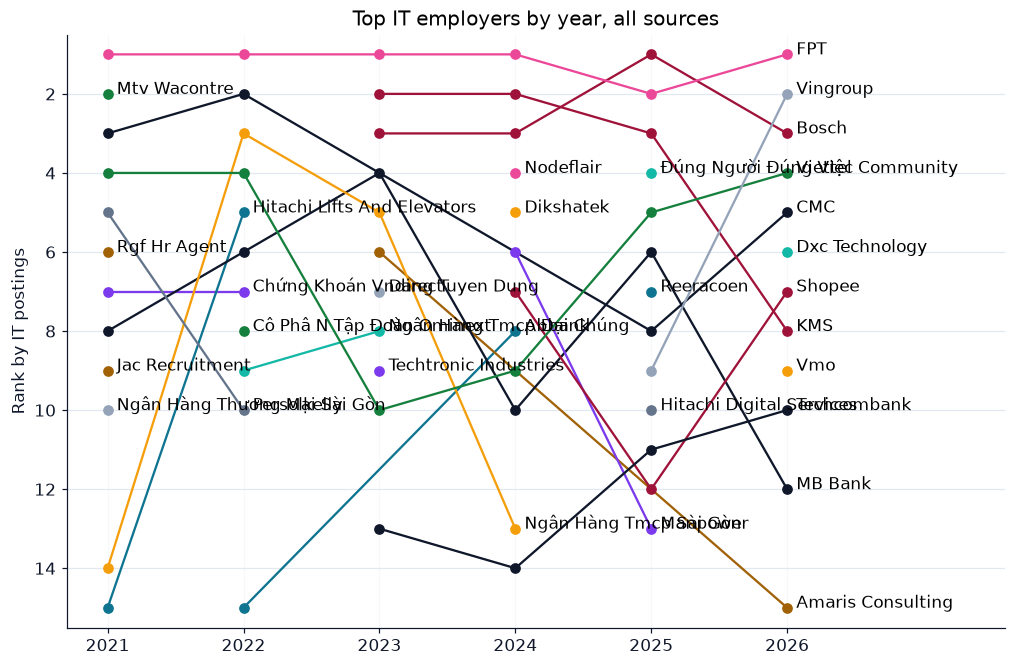

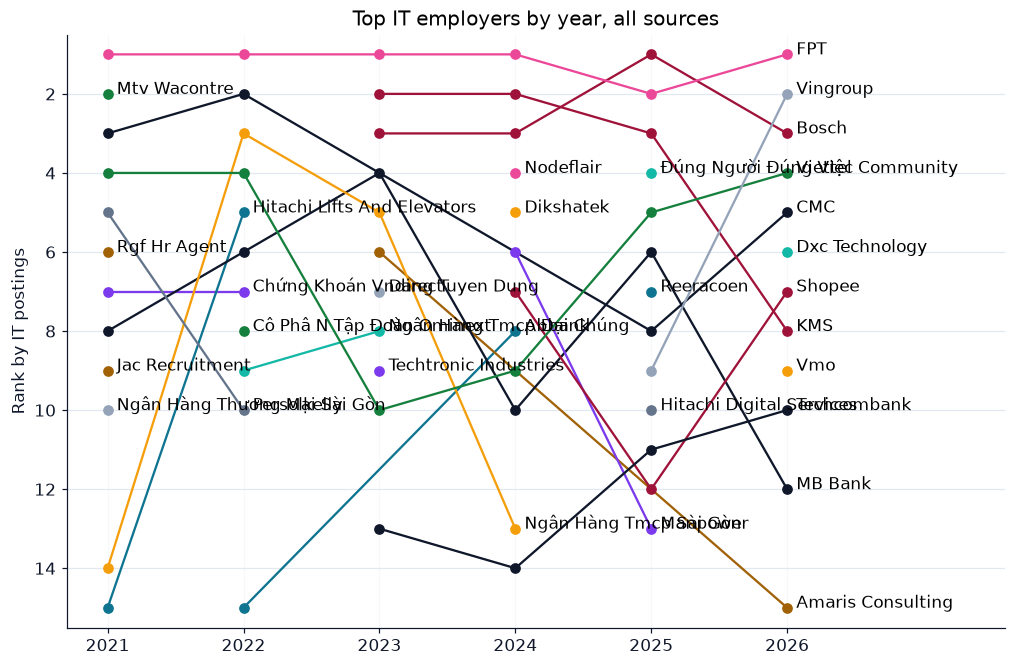

In [2]:
fig = e.chart_bump(rankings["All sources"], "Top IT employers by year, all sources")
a.save_chart(fig, "17-bump-all-sources")
fig

## 2. CareerBuilder

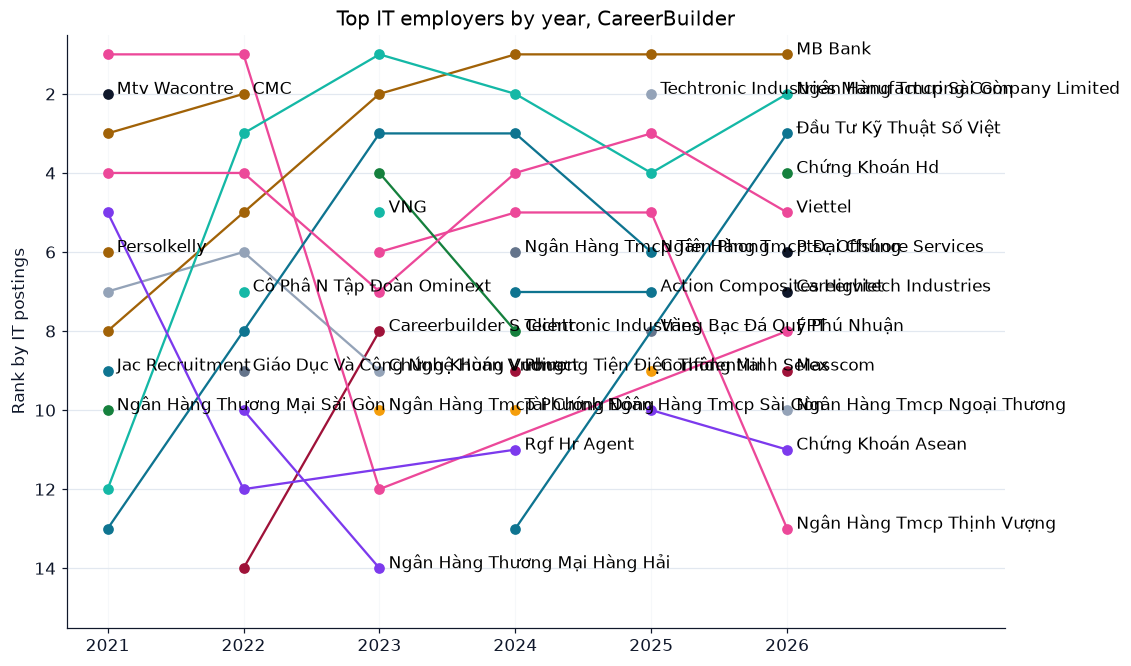

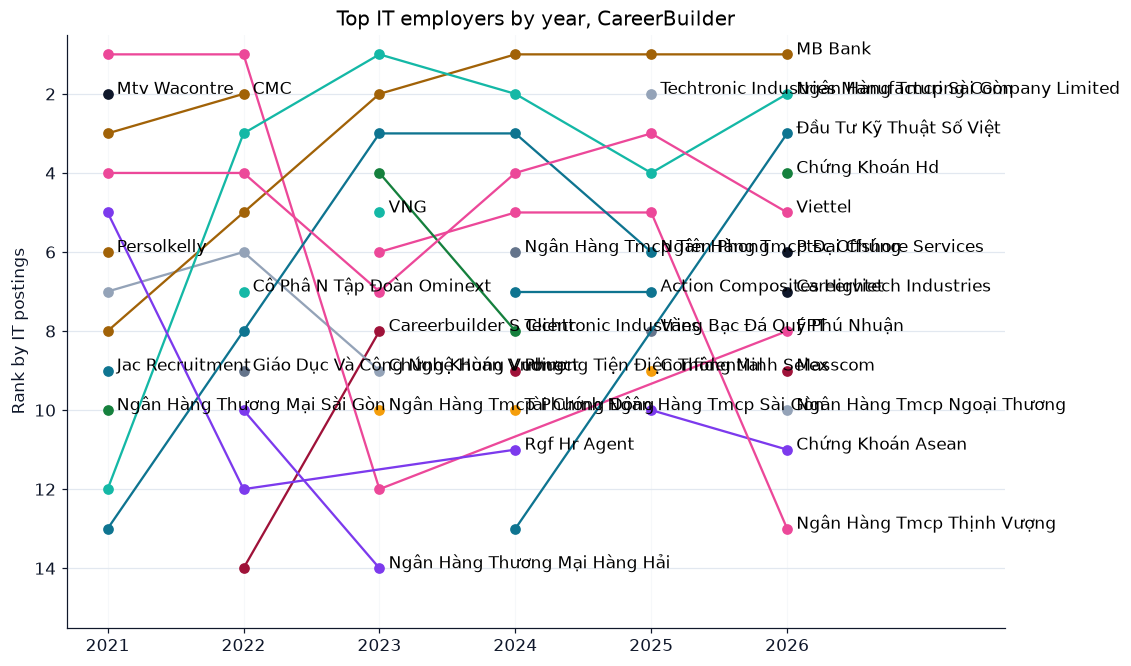

In [3]:
fig = e.chart_bump(rankings["CareerBuilder"], "Top IT employers by year, CareerBuilder")
a.save_chart(fig, "17-bump-careerbuilder")
fig

## 3. LinkedIn

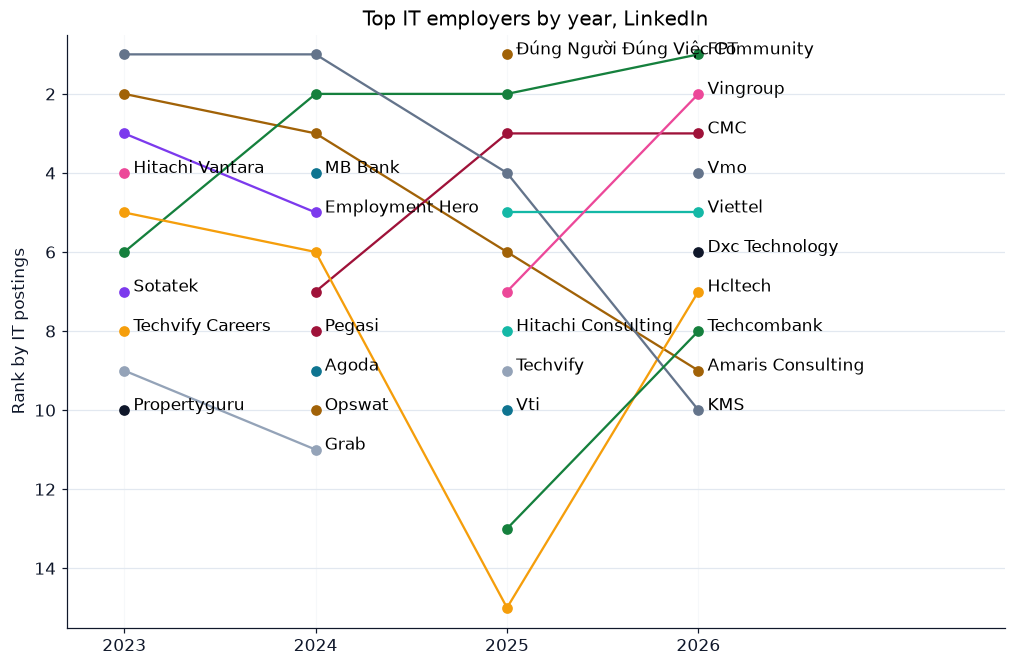

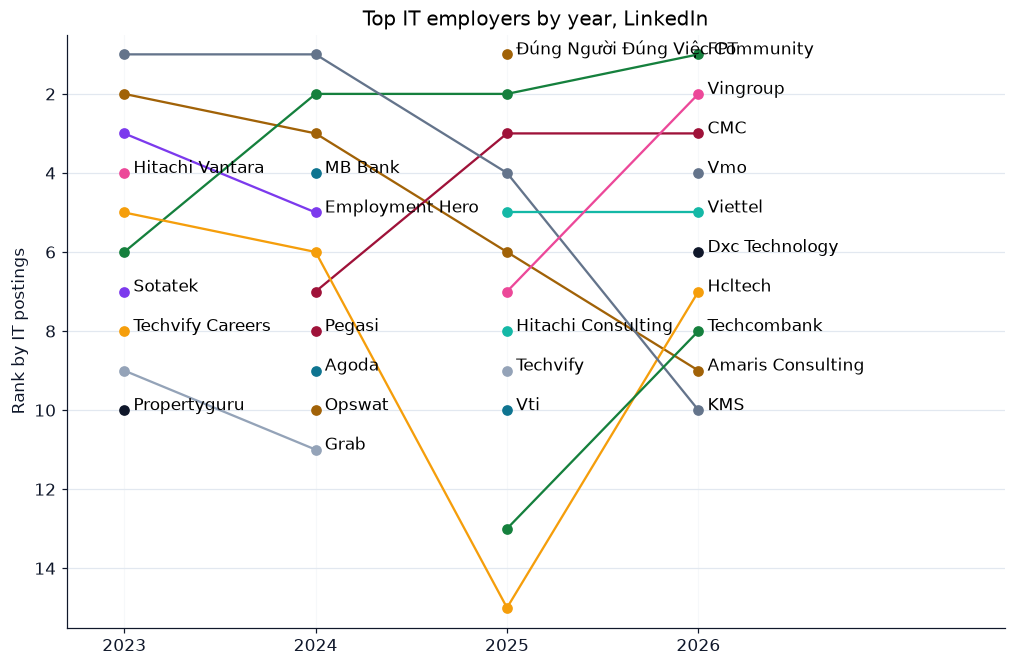

In [4]:
fig = e.chart_bump(rankings["LinkedIn"], "Top IT employers by year, LinkedIn")
a.save_chart(fig, "17-bump-linkedin")
fig

## 4. Who keeps returning to the top

In [5]:
summary = {name: e.years_in_top(r) for name, r in rankings.items()}
for name, frame in summary.items():
    a.save_table(frame, "17-years-in-top-" + name.lower().replace(" ", "-"))
summary["All sources"].head(12)

,company,years_in_top,best_rank
0,FPT,6,1
1,Viettel,6,4
2,MB Bank,5,4
3,Bosch,4,1
4,CMC,4,2
5,KMS,4,2
6,Vingroup,2,2
7,Ngân Hàng Tmcp Sài Gòn,2,3
8,Persolkelly,2,5
9,Chứng Khoán Vndirect,2,7


In [6]:
summary["LinkedIn"].head(8)

,company,years_in_top,best_rank
0,FPT,4,1
1,KMS,4,1
2,Amaris Consulting,4,2
3,CMC,3,3
4,Hcltech,3,5
5,Vingroup,2,2
6,Employment Hero,2,3
7,Viettel,2,5


In [7]:
summary["CareerBuilder"].head(8)

,company,years_in_top,best_rank
0,MB Bank,6,1
1,Viettel,6,3
2,Ngân Hàng Tmcp Sài Gòn,5,1
3,Ngân Hàng Tmcp Đại Chúng,4,3
4,FPT,3,1
5,Ngân Hàng Tmcp Thịnh Vượng,3,5
6,Chứng Khoán Vndirect,3,6
7,CMC,2,2


## 5. The leader's share each year

In [8]:
top = pd.concat([r[r["rank"] == 1].assign(scope=n) for n, r in rankings.items()])[
    ["scope", "year", "company", "postings", "share"]
]
a.save_table(top, "17-leader-by-year")
top

,scope,year,company,postings,share
302,All sources,2021,FPT,244,4.75
1669,All sources,2022,FPT,436,4.57
4913,All sources,2023,FPT,519,2.04
12459,All sources,2024,FPT,912,2.93
19559,All sources,2025,Bosch,637,1.85
29122,All sources,2026,FPT,886,2.43
288,CareerBuilder,2021,FPT,244,5.06
1613,CareerBuilder,2022,FPT,436,4.94
3840,CareerBuilder,2023,Ngân Hàng Tmcp Sài Gòn,193,2.81
5159,CareerBuilder,2024,MB Bank,149,3.45


## Findings

1. **FPT leads five years out of six.** First in every year except 2025 across all sources; FPT and Viettel are the two employers in the top ten all six years. FPT's share of named postings fell from 4.75 % (2021) to 2.4 % (2026), so even the leader holds a smaller slice. (Re-run 2026-11-08 after `company_group` started matching group names anywhere in the name, not only as a prefix.)
2. **Only 2025 has another leader.** Bosch leads 2025 (637 postings against FPT's 618). KMS is second in 2023 and 2024. MB Bank is in the top ten five years. Vingroup climbs to second in 2026 on both all sources and LinkedIn.
3. **Who is on top depends on the board.** CareerBuilder is a bank list: MB Bank and Viettel are in its top ten all six years and a Sài Gòn bank five, with FPT in three. LinkedIn is a software-house list: FPT, KMS and Amaris Consulting each four years. A single all-source ranking mixes the two, which is why the ranking is drawn for all three scopes.
4. **Caveats.** 2021 names a company on only 44 % of postings, and 2026 stops at October. Names are the normalised company key, title-cased, so a few read oddly. LinkedIn's first place in 2025, "Đúng Người Đúng Việc Community", looks like a recruitment community rather than an employer; it has not been checked and should not be quoted. The bump charts are for checking: labels collide, and the video version is rebuilt from the tables.

**What this notebook cannot say:** how many people an employer actually hired. Each posting is one vacancy ad, and an employer can repost one role many times.